In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

**Load dataset**

In [4]:
df = pd.read_csv("employee_performance.csv")
print("Shape :", df.shape)
df.head()

Shape : (4000, 8)


,Employee_ID,Department,Age,Salary,Projects_Completed,Working_Hours,Performance_Score,Promotion_Status
0,E1000,Marketing,26,59300,5,49.5,67.1,Yes
1,E1001,Finance,22,61800,11,39.2,73.6,Yes
2,E1002,Marketing,45,88700,7,35.3,74.8,Yes
3,E1003,Sales,53,90200,9,53.8,89.8,No
4,E1004,HR,30,60200,6,39.9,70.5,No


In [5]:
df.info()
print("===============================================")

print("\nMissing values per column:\n", df.isna().sum())

print("===============================================")

print("\nDuplicate Employee_IDs:", df["Employee_ID"].duplicated().sum())

print("===============================================")

df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         4000 non-null   str    
 1   Department          4000 non-null   str    
 2   Age                 4000 non-null   int64  
 3   Salary              4000 non-null   int64  
 4   Projects_Completed  4000 non-null   int64  
 5   Working_Hours       4000 non-null   float64
 6   Performance_Score   4000 non-null   float64
 7   Promotion_Status    4000 non-null   str    
dtypes: float64(2), int64(3), str(3)
memory usage: 250.1 KB

Missing values per column:
 Employee_ID           0
Department            0
Age                   0
Salary                0
Projects_Completed    0
Working_Hours         0
Performance_Score     0
Promotion_Status      0
dtype: int64

Duplicate Employee_IDs: 0


,Age,Salary,Projects_Completed,Working_Hours,Performance_Score
count,4000.00,4000.00,4000.00,4000.00,4000.00
mean,34.18,81632.73,8.04,43.82,63.72
std,7.63,15816.94,2.87,4.95,11.86
min,21.00,44800.00,0.00,30.00,27.20
25%,29.00,70500.00,6.00,40.50,55.80
50%,34.00,80500.00,8.00,43.80,63.70
75%,39.00,90800.00,10.00,47.00,71.90
max,60.00,252400.00,21.00,62.10,100.00


In [6]:
# Promotion_Status for probability work

df["Promoted"] = (df["Promotion_Status"].str.strip().str.lower() == "yes").astype(int)
df["Promoted"].value_counts()

Promoted
0    3430
1     570
Name: count, dtype: int64

**Step 1: Central Tendency & Dispersion** 

In [7]:
print("Salary Mean   :", df["Salary"].mean())
print("Salary Median :", df["Salary"].median())
print("Salary Mode   :", df["Salary"].mode().tolist())   
 
print("Projects_Completed Variance :", df["Projects_Completed"].var())   
print("Projects_Completed Std Dev  :", df["Projects_Completed"].std())

Salary Mean   : 81632.725
Salary Median : 80500.0
Salary Mode   : [74700, 79500]
Projects_Completed Variance : 8.260572080520129
Projects_Completed Std Dev  : 2.8741210970521283


**Step 2: Probability & Events**

In [8]:
p_promo = df["Promoted"].mean()
print("P(Promotion) =", round(p_promo, 4))
 
contingency = pd.crosstab(df["Department"], df["Promotion_Status"], margins=True)
print("\nContingency table (Department vs Promotion_Status):\n", contingency)
 
high = df[df["Performance_Score"] > 80]
p_cond = high["Promoted"].mean()

print("\nP(Promotion | Performance_Score > 80) =", round(p_cond, 4))
print("Compare with P(Promotion) =", round(p_promo, 4))

P(Promotion) = 0.1425

Contingency table (Department vs Promotion_Status):
 Promotion_Status    No  Yes   All
Department                       
Finance            540   69   609
HR                 357   49   406
IT                1017  183  1200
Marketing          415   78   493
Operations         444   77   521
Sales              657  114   771
All               3430  570  4000

P(Promotion | Performance_Score > 80) = 0.531
Compare with P(Promotion) = 0.1425


**Step 3: Distributions & Visualization**

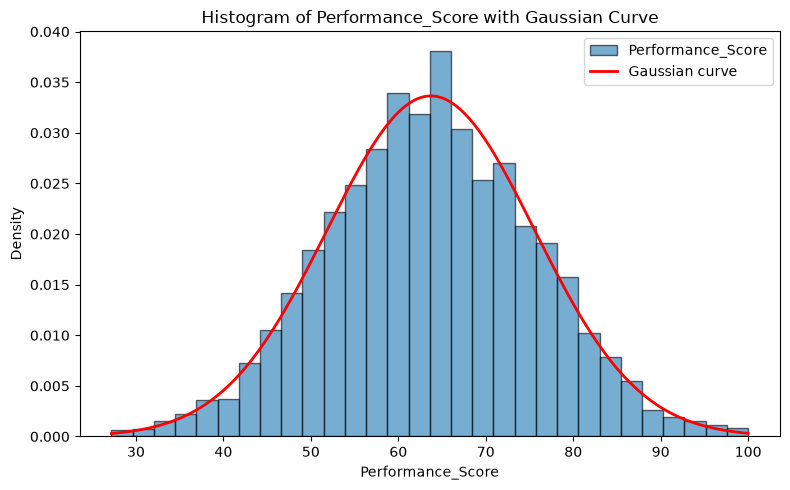

Salary Skewness : 1.1567054654753393
Salary Kurtosis (excess) : 6.21533744751612


In [9]:
scores = df["Performance_Score"].dropna()
mu, sigma = scores.mean(), scores.std()
 
plt.figure(figsize=(8, 5))
plt.hist(scores, bins=30, density=True, alpha=0.6, edgecolor="black", label="Performance_Score")
x = np.linspace(scores.min(), scores.max(), 300)
plt.plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2, label="Gaussian curve")
plt.title("Histogram of Performance_Score with Gaussian Curve")
plt.xlabel("Performance_Score")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig("histogram_performance.png", dpi=150)
plt.show()
 
print("Salary Skewness :", stats.skew(df["Salary"]))
print("Salary Kurtosis (excess) :", stats.kurtosis(df["Salary"]))

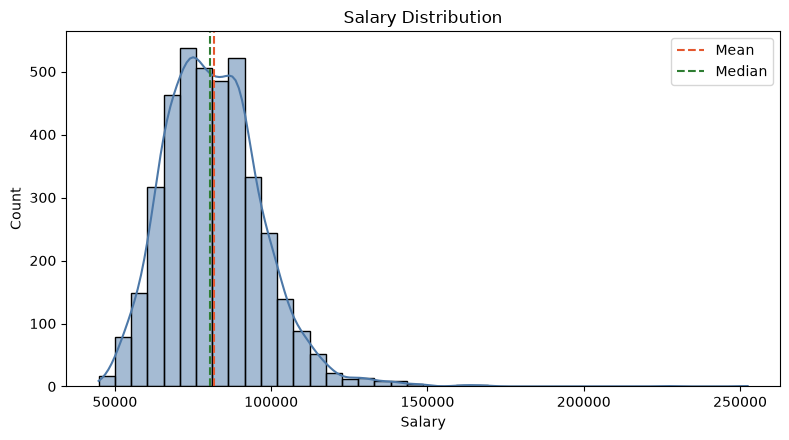

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.histplot(df["Salary"], bins=40, kde=True, color="#4C78A8", ax=ax)
ax.axvline(df["Salary"].mean(), color="#E4572E", ls="--", label="Mean")
ax.axvline(df["Salary"].median(), color="#2E7D32", ls="--", label="Median")
ax.set_title("Salary Distribution"); 
ax.legend()
plt.tight_layout(); 
plt.savefig("salary_distribution.png", dpi=150); 

plt.show()

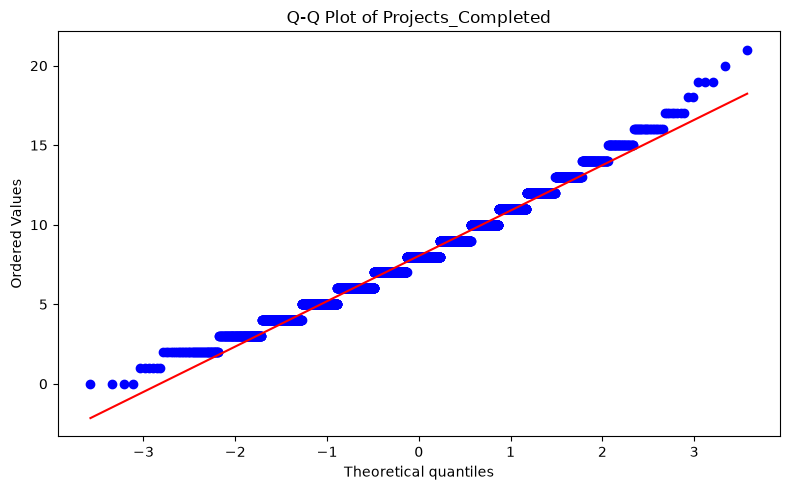

In [11]:
plt.figure(figsize=(8, 5))
stats.probplot(df["Projects_Completed"], dist="norm", plot=plt)
plt.title("Q-Q Plot of Projects_Completed")
plt.tight_layout()
plt.savefig("qqplot_projects.png", dpi=150)
plt.show()

**Step 4: Linear Algebra**

In [12]:
vecs = df.loc[:4, ["Projects_Completed", "Working_Hours"]].to_numpy(dtype=float)
print("First 5 work vectors:\n", vecs)
 
a, b = vecs[0], vecs[1]          # employee 1 and employee 2
dot = np.dot(a, b)
print("\nDot product (emp1 . emp2):", dot)
 
print("Norm 1 (L1) of emp1:", np.linalg.norm(a, 1))
print("Norm 2 (L2) of emp1:", np.linalg.norm(a, 2))
 
cos_theta = dot / (np.linalg.norm(a) * np.linalg.norm(b))
angle = np.degrees(np.arccos(np.clip(cos_theta, -1, 1)))

print("Cosine similarity:", cos_theta)
print("Angle between emp1 and emp2 (degrees):", angle)

First 5 work vectors:
 [[ 5.  49.5]
 [11.  39.2]
 [ 7.  35.3]
 [ 9.  53.8]
 [ 6.  39.9]]

Dot product (emp1 . emp2): 1995.4
Norm 1 (L1) of emp1: 54.5
Norm 2 (L2) of emp1: 49.751884386422994
Cosine similarity: 0.9850886705034675
Angle between emp1 and emp2 (degrees): 9.906881177095427


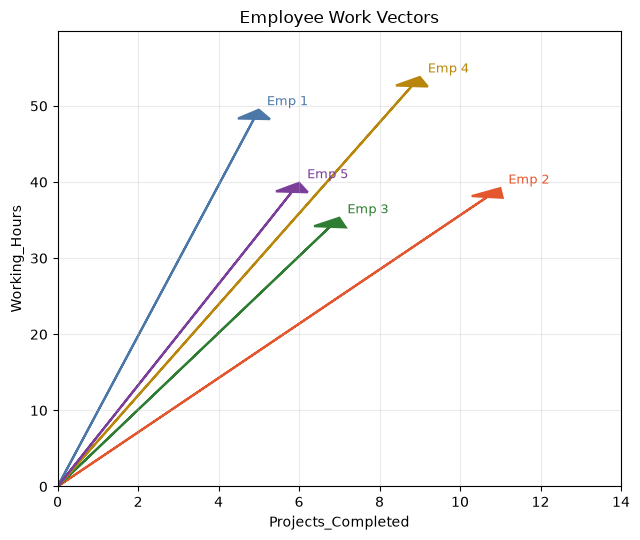

In [13]:
# Visualize the five work vectors

fig, ax = plt.subplots(figsize=(6.5, 5.5))

colors = ["#4C78A8","#E4572E","#2E7D32","#B8860B","#7B3F99"]

for i,(v,c) in enumerate(zip(vecs, colors)):
    ax.arrow(0, 0, v[0], v[1], head_width=0.8, length_includes_head=True, color=c, lw=1.6)
    ax.text(v[0]+0.2, v[1]+0.6, f"Emp {i+1}", color=c, fontsize=9)
    
ax.set_xlim(0, vecs[:,0].max()+3); 
ax.set_ylim(0, vecs[:,1].max()+6)
ax.set_xlabel("Projects_Completed"); 
ax.set_ylabel("Working_Hours")
ax.set_title("Employee Work Vectors"); 
ax.grid(alpha=0.25)
plt.tight_layout(); 
plt.savefig("work_vectors.png", dpi=150);

plt.show()